In [2]:
import pandas as pd
import numpy as np
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

In [3]:
starbucks = pd.read_csv("directory.csv")
starbucks.head()

,Brand,Store Number,Store Name,Ownership Type,Street Address,City,State/Province,Country,Postcode,Phone Number,Timezone,Longitude,Latitude
0,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra la Vella,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51
1,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42
2,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39
3,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48
4,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51


查看星巴克旗下有哪些品牌，筛选星巴克品牌数据

In [4]:
print("星巴克旗下品牌有:\n", starbucks.Brand.value_counts())
coffee = starbucks[starbucks.Brand == 'Starbucks']
print("\n", coffee.shape)

星巴克旗下品牌有:
 Brand
Starbucks                25249
Teavana                    348
Evolution Fresh              2
Coffee House Holdings        1
Name: count, dtype: int64

 (25249, 13)


查看全球星巴克门店国家/地区数量及排名

In [5]:
df = starbucks.groupby(["Country"]).size()
print("全世界一共有多少个国家和地区开设了星巴克门店:", df.size)
df1 = df.sort_values(ascending = False)
print("排名前10的国家和地区:\n", df1.head(10))
print("排名后10的国家:\n", df1.tail(10))

全世界一共有多少个国家和地区开设了星巴克门店: 73
排名前10的国家和地区:
 Country
US    13608
CN     2734
CA     1468
JP     1237
KR      993
GB      901
MX      579
TW      394
TR      326
PH      298
dtype: int64
排名后10的国家:
 Country
AZ    4
KH    4
TT    3
AW    3
CW    3
SK    3
ZA    3
LU    2
MC    2
AD    1
dtype: int64


绘制排名前10的国家/地区分布柱状图

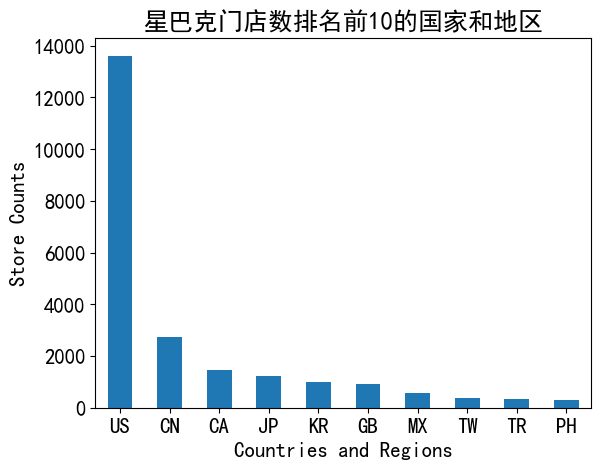

In [6]:
plt.rcParams['font.size'] = 15
plt.rcParams['font.family'] = 'SimHei'
df1.head(10).plot(kind = 'bar', rot = 0)
plt.title('星巴克门店数排名前10的国家和地区')
plt.ylabel('Store Counts')
plt.xlabel('Countries and Regions')
plt.show()

显示拥有星巴克门店数量排名前10的城市

In [7]:
count_starbucks_city = coffee.City.value_counts()
print("星巴克门店数量排名前10的城市:\n", count_starbucks_city.head(10))
star = starbucks.dropna(how = 'any', subset = ['City'])
count_starbucks_city = star.City.value_counts()
print("全世界星巴克门店数量排名前10的城市:\n", count_starbucks_city.head(10))


星巴克门店数量排名前10的城市:
 City
上海市            542
Seoul          243
北京市            234
New York       230
London         215
Toronto        186
Mexico City    180
Chicago        179
Las Vegas      153
Seattle        151
Name: count, dtype: int64
全世界星巴克门店数量排名前10的城市:
 City
上海市            542
Seoul          243
北京市            234
New York       232
London         216
Toronto        192
Chicago        180
Mexico City    180
Seattle        156
Las Vegas      156
Name: count, dtype: int64


绘制星巴克门店数前10的城市分布柱状图

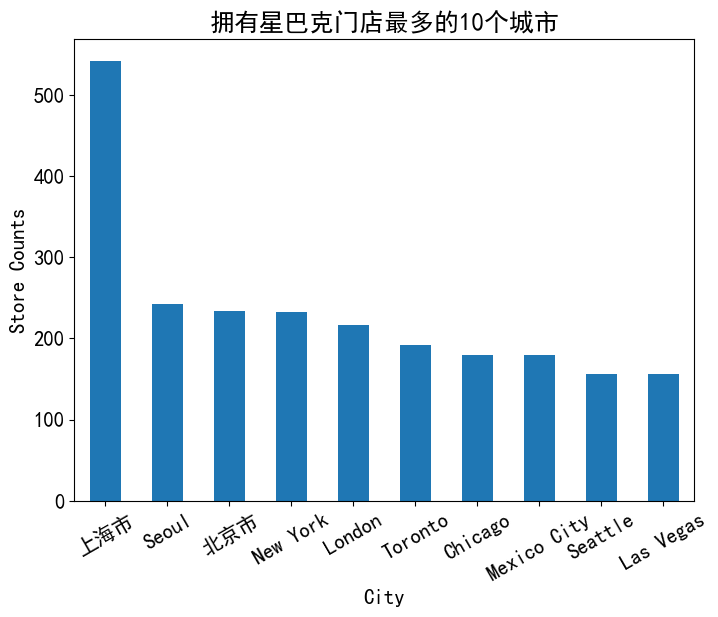

In [8]:
plt.figure(1, figsize = (8,6))
count_starbucks_city = star.City.value_counts()
city_top10 = count_starbucks_city.head(10)
city_top10.plot(kind = 'bar', rot = 30)
plt.title('拥有星巴克门店最多的10个城市')
plt.ylabel('Store Counts')
plt.xlabel('City')
plt.show()

按照星巴克门店在中国的分布，统计排名前10的城市

In [9]:
import pinyin
# 选择中国的数据
df = star[star["Country"] == "CN"]
df1 = df.copy()
# 将城市名改为小写
df1["City"] = df1["City"].apply(lambda x:x.lower())
# 将汉字城市名改为小写拼音，去掉"市"的拼音
df1["City"] = df1["City"].apply(lambda x:pinyin.get(x, format = "strip", delimiter = "")[0:-3])
# 统计每个城市的星巴克门店数量
df1 = df1.groupby(["City"]).size().sort_values(ascending = False)
df1.head(10)


City
shanghai     542
beijing      234
hangzhou     117
shenzhen     113
guangzhou    106
hong k       104
chengdu       98
suzhou        90
nanjing       73
wuhan         67
dtype: int64

绘制柱状图

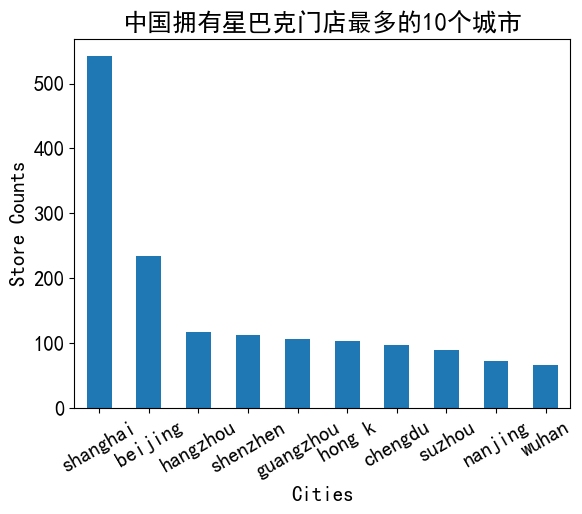

In [10]:
df1.head(10).plot(kind = 'bar', rot = 30)
plt.title('中国拥有星巴克门店最多的10个城市')
plt.ylabel('Store Counts')
plt.xlabel('Cities')
plt.show()

 用饼状图显示星巴克门店的经营方式

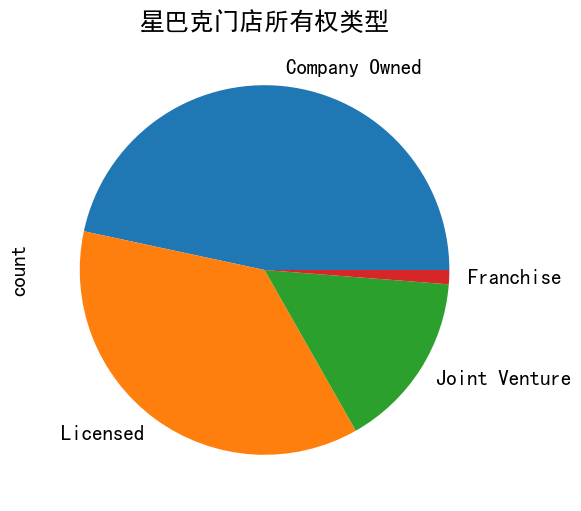

In [11]:
ownership = star['Ownership Type'].value_counts()
plt.figure(1, figsize = (8,6))
plt.title('星巴克门店所有权类型')
ownership.plot(kind = 'pie')
plt.show()